# Análisis Evolutivo: Wolf Sheep Predation

**Modelo:** Wolf Sheep Predation (NetLogo Library)

**Variante:** `sheep-wolves` (sin pasto)

**Parámetro analizado:** `initial-number-sheep` — número inicial de ovejas.

**Pregunta experimental:** ¿Cómo evoluciona la población de ovejas a lo largo del tiempo para diferentes valores iniciales en el modelo de depredación lobo-oveja?


## Variables del experimento

| Elemento | Valor |
|---|---|
| Variable independiente | `initial-number-sheep` (20, 40, 60, …, 200) |
| Variable dependiente temporal | `count sheep` (número de ovejas vivas en cada tick) |
| Variable de tiempo | `[step]` (tick actual) |
| Número de repeticiones | 30 por valor del parámetro |
| Condición de parada | No quedan turtles, o no quedan lobos y `count sheep > max-sheep` (30.000) |
| Archivo CSV | `wolfsheep_evol.csv` |


In [13]:
library(tidyverse)

## 1. Cargar datos evolutivos

In [14]:
url <- "https://raw.githubusercontent.com/juandrodriguezf/wolf-sheep-predation-netlogo/master/wolf_sheep/wolfsheep_evol.csv"
data <- read.csv(url, encoding = "UTF-8", skip = 6)

In [15]:
head(data)
names(data)
glimpse(data)

,X.run.number.,initial.number.sheep,X.step.,count.sheep
,<int>,<int>,<int>,<int>
1,8,160,0,160
2,4,80,0,80
3,7,140,0,140
4,9,180,0,180
5,2,40,0,40
6,3,60,0,60


[1] "X.run.number."        "initial.number.sheep" "X.step."             
[4] "count.sheep"

Rows: 116,469
Columns: 4
$ X.run.number.        <int> 8, 4, 7, 9, 2, 3, 11, 12, 10, 5, 6, 2, 9, 4, 7, 8…
$ initial.number.sheep <int> 160, 80, 140, 180, 40, 60, 20, 40, 200, 100, 120,…
$ X.step.              <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1…
$ count.sheep          <int> 160, 80, 140, 180, 40, 60, 20, 40, 200, 100, 120,…


## 2. Renombrar columnas

In [16]:
colnames(data) <- c("corrida", "parametro", "tiempo", "valor_temporal")
head(data)

,corrida,parametro,tiempo,valor_temporal
,<int>,<int>,<int>,<int>
1,8,160,0,160
2,4,80,0,80
3,7,140,0,140
4,9,180,0,180
5,2,40,0,40
6,3,60,0,60


## 3. Seleccionar columnas relevantes

In [17]:
datas <- data %>% select(parametro, tiempo, valor_temporal)
head(datas)

,parametro,tiempo,valor_temporal
,<int>,<int>,<int>
1,160,0,160
2,80,0,80
3,140,0,140
4,180,0,180
5,40,0,40
6,60,0,60


## 4. Primera vista

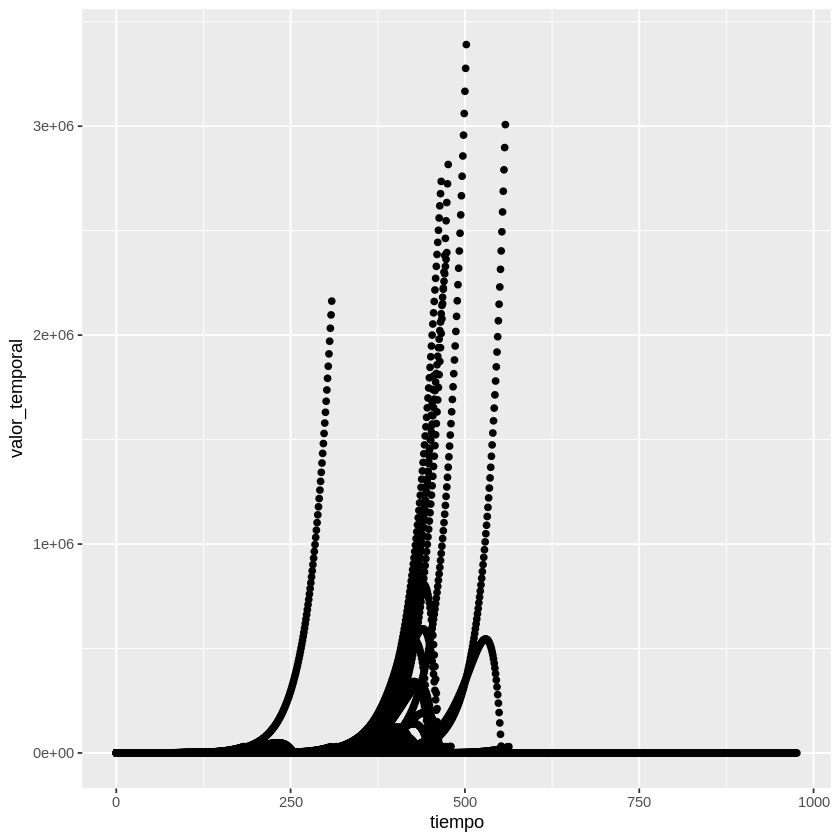

In [18]:
datas %>%
  ggplot(aes(tiempo, valor_temporal)) +
  geom_point()

## 5. Vista diferenciada por parámetro

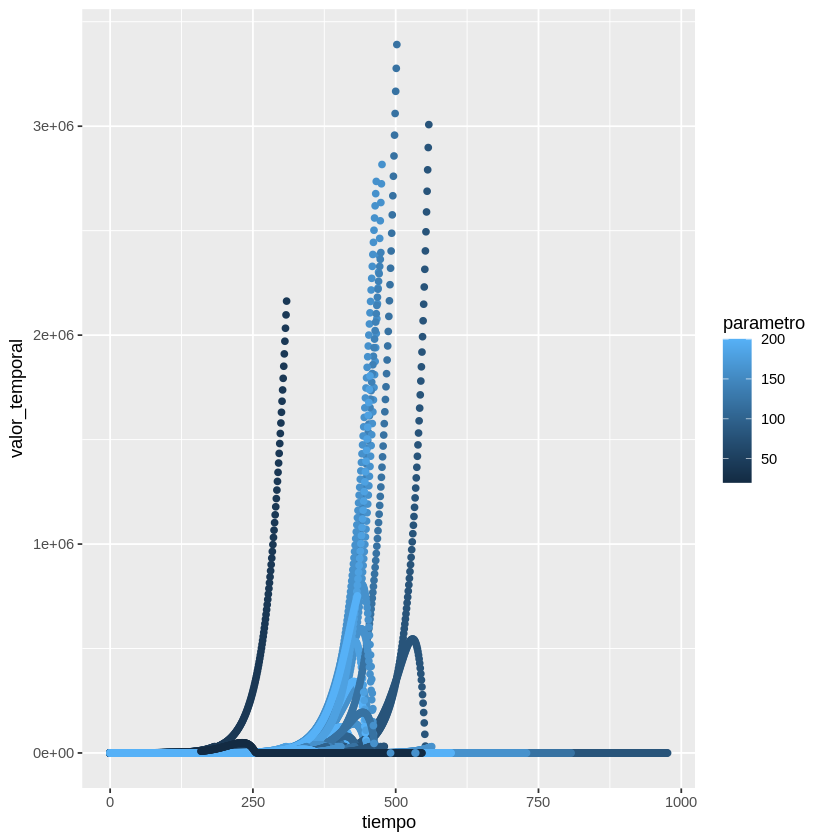

In [19]:
datas %>%
  ggplot(aes(tiempo, valor_temporal)) +
  geom_point(aes(color = parametro))

## 6. Promedio por parámetro y tiempo

In [20]:
datag <- datas %>%
  group_by(parametro, tiempo) %>%
  summarize(promedio = mean(valor_temporal), .groups = "drop")
head(datag)

parametro,tiempo,promedio
<int>,<int>,<dbl>
20,0,20.00000
20,1,20.53333
20,2,20.76667
20,3,21.03333
20,4,21.80000
20,5,22.33333


## 7. Curvas de evolución temporal

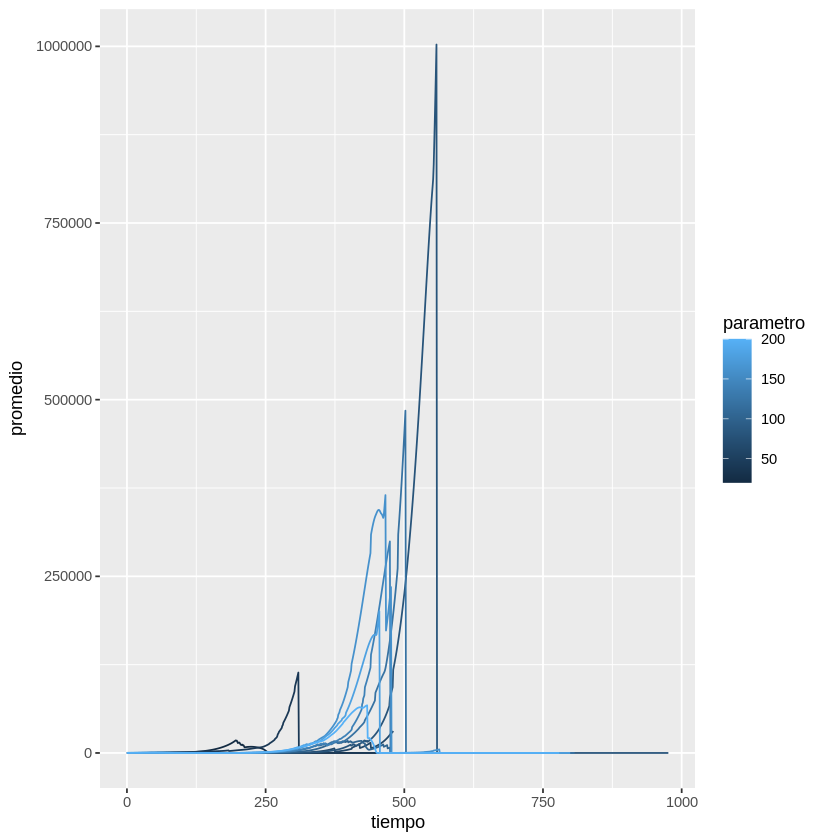

In [21]:
datag %>%
  ggplot(aes(tiempo, promedio)) +
  geom_line(aes(group = parametro, color = parametro))

## 8. Facetas por valor del parámetro

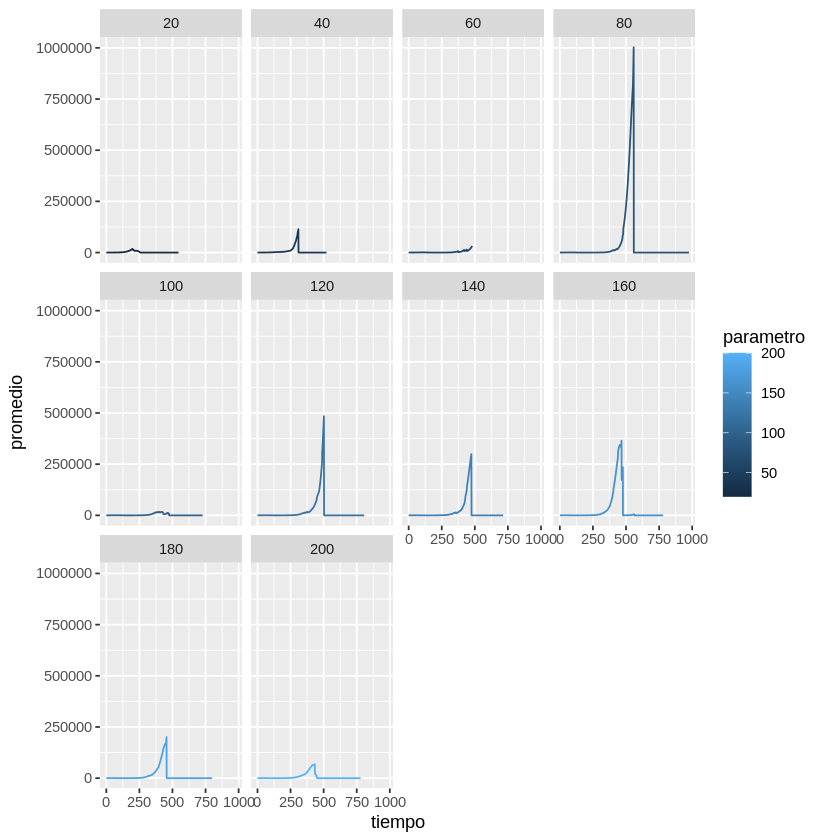

In [22]:
datag %>%
  ggplot(aes(tiempo, promedio)) +
  geom_line(aes(color = parametro)) +
  facet_wrap(~ parametro)

## 9. Interpretación

Las gráficas muestran el promedio de ovejas vivas por tick para cada valor de `initial-number-sheep`. El promedio se calcula solo con las corridas que siguen activas en cada tick, por lo que después de los primeros colapsos la muestra se reduce y los valores tardíos deben interpretarse con cautela. Para describir la forma de las curvas se usan medianas calculadas a partir del CSV, porque el promedio está dominado por valores extremos.

**Tendencia general:** La población no desciende de forma simple. En la mayoría de los grupos crece rápidamente, alcanza un pico y colapsa; en algunos casos hay un nuevo crecimiento. Por ejemplo, con 20 ovejas iniciales la mediana pasa de 20 (tick 0) a 92 (tick 50), 628 (tick 100) y 3.871 (tick 150); con 100 ovejas llega a 486 (tick 75) y cae a 4 (tick 150).

**Efecto del parámetro:** El número inicial cambia la escala y el momento de los picos, pero no elimina el patrón de auge y caída. Las poblaciones grandes tienden a sostener la simulación por más tiempo (medianas de ~364 a ~435 ticks entre 140 y 200), aunque con una variabilidad muy alta.

**Dos desenlaces:** Cada corrida termina en colapso (ovejas = 0) o en desborde (lobos extintos y ovejas > 30.000). La proporción cambia con el parámetro: con 40 predominan los colapsos (28 de 30) y con 180 los desbordes (22 de 30). El máximo observado fue 3.390.767 ovejas. Esta mezcla explica por qué `ticks` no muestra una relación monótona.

**Sesgo de supervivencia:** Al promediar por tick solo contribuyen las corridas que siguen vivas; los picos de millones corresponden a pocas corridas y no representan al conjunto. Por eso las curvas promedio deben complementarse con trayectorias individuales o medianas.

**Conexión con las reglas locales:** En la variante `sheep-wolves` las ovejas se reproducen con probabilidad fija y solo mueren cuando un lobo las caza; los lobos pierden energía, cazan y mueren si se quedan sin ella. Cuando los lobos desaparecen, las ovejas crecen sin control hasta la condición de parada; cuando la depredación es intensa, las ovejas colapsan.
